In [5]:
from pathlib import Path
import pandas as pd
import json

# Locate the repository root
ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data/processed/training_handoff/development.csv").exists()),
    None
)

if ROOT is None:
    raise FileNotFoundError("Cannot locate the Posters repository.")

# Load development data
df = pd.read_csv(
    ROOT / "data/processed/training_handoff/development.csv"
)

# Load predefined feature groups
with open(ROOT / "data/processed/feature_sets_v1.json") as f:
    feature_sets = json.load(f)

# Select the 12 visual features
visual_features = feature_sets["visual_baseline"]

X = df[visual_features]
y = df["y_active_mid_count"]

print("X shape:", X.shape)
print("y shape:", y.shape)

display(df.head())


X shape: (51, 12)
y shape: (51,)


,poster_year,target_year,n_posters,red_ratio_mean,red_ratio_n_valid,red_ratio_missing_ratio,r_mean_mean,r_mean_n_valid,r_mean_missing_ratio,g_mean_mean,...,archive_tag_agriculture_n_valid,archive_tag_agriculture_missing_ratio,archive_tag_mao_mean,archive_tag_mao_n_valid,archive_tag_mao_missing_ratio,archive_tag_red_flag_mean,archive_tag_red_flag_n_valid,archive_tag_red_flag_missing_ratio,y_active_mid_count,split
0,1949,1950,10,0.230524,10,0.0,0.581460,10,0.0,0.425264,...,10,0.0,0.200000,10,0.0,0.200000,10,0.0,6,development
1,1950,1951,26,0.063322,26,0.0,0.719032,26,0.0,0.669839,...,26,0.0,0.192308,26,0.0,0.153846,26,0.0,3,development
2,1951,1952,60,0.074302,60,0.0,0.667969,60,0.0,0.591164,...,60,0.0,0.083333,60,0.0,0.083333,60,0.0,3,development
3,1952,1953,98,0.048475,98,0.0,0.675367,98,0.0,0.610160,...,98,0.0,0.040816,98,0.0,0.051020,98,0.0,5,development
4,1953,1954,116,0.055321,116,0.0,0.634614,116,0.0,0.557587,...,116,0.0,0.051724,116,0.0,0.034483,116,0.0,6,development


count    51.000000
mean      3.352941
std       2.170931
min       0.000000
25%       2.000000
50%       3.000000
75%       5.000000
max      10.000000
Name: y_active_mid_count, dtype: float64


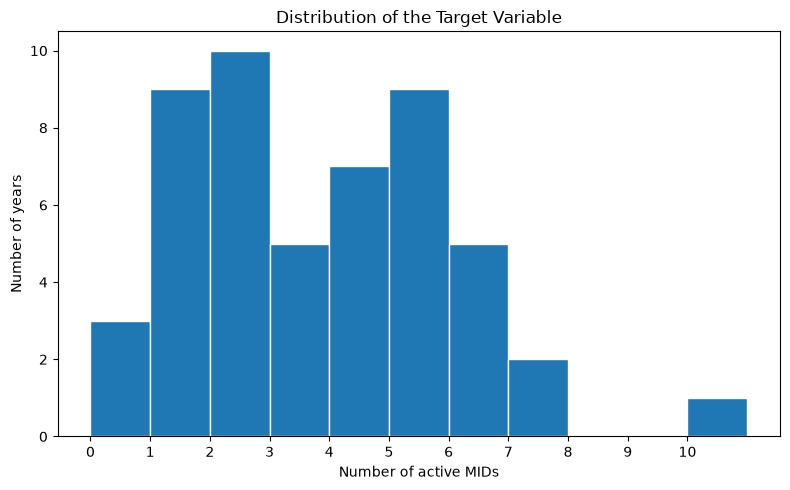

In [6]:
import matplotlib.pyplot as plt

print(y.describe())

plt.figure(figsize=(8, 5))
plt.hist(y, bins=range(12), edgecolor="white")

plt.xlabel("Number of active MIDs")
plt.ylabel("Number of years")
plt.title("Distribution of the Target Variable")
plt.xticks(range(11))
plt.tight_layout()
plt.show()


In [7]:
# Summary statistics for the 12 visual features
display(X.describe().T)

# Check missing values
print("Missing values:")
display(X.isna().sum())

# Check data types
print("Data types:")
display(X.dtypes)

,count,mean,std,min,25%,50%,75%,max
red_ratio_mean,51.0,0.114687,0.051677,0.048475,0.080405,0.100032,0.140486,0.282872
r_mean_mean,51.0,0.665075,0.033767,0.581460,0.647659,0.659412,0.680743,0.788598
g_mean_mean,51.0,0.579863,0.049072,0.425264,0.548972,0.581591,0.603518,0.744285
b_mean_mean,51.0,0.515753,0.062088,0.336440,0.474749,0.511794,0.546185,0.726500
saturation_mean_mean,51.0,0.305027,0.048853,0.154379,0.280440,0.298265,0.327040,0.437727
lightness_mean_mean,51.0,62.374555,4.142681,49.589322,59.767185,62.178627,64.490293,77.018163
lightness_std_mean,51.0,24.503068,1.671583,19.546000,23.446912,24.691355,25.600615,27.408779
lightness_p90_p10_mean,51.0,64.665982,4.554426,50.709250,60.964452,65.648069,68.105406,73.366994
size_short_cm_mean,51.0,51.498721,5.323919,30.711538,49.294955,52.636364,54.259384,61.915094
size_long_cm_mean,51.0,76.123111,8.278436,42.326923,72.707190,77.558333,79.978628,93.250000


Missing values:


red_ratio_mean            0
r_mean_mean               0
g_mean_mean               0
b_mean_mean               0
saturation_mean_mean      0
lightness_mean_mean       0
lightness_std_mean        0
lightness_p90_p10_mean    0
size_short_cm_mean        0
size_long_cm_mean         0
size_area_cm2_mean        0
size_aspect_ratio_mean    0
dtype: int64

Data types:


red_ratio_mean            float64
r_mean_mean               float64
g_mean_mean               float64
b_mean_mean               float64
saturation_mean_mean      float64
lightness_mean_mean       float64
lightness_std_mean        float64
lightness_p90_p10_mean    float64
size_short_cm_mean        float64
size_long_cm_mean         float64
size_area_cm2_mean        float64
size_aspect_ratio_mean    float64
dtype: object

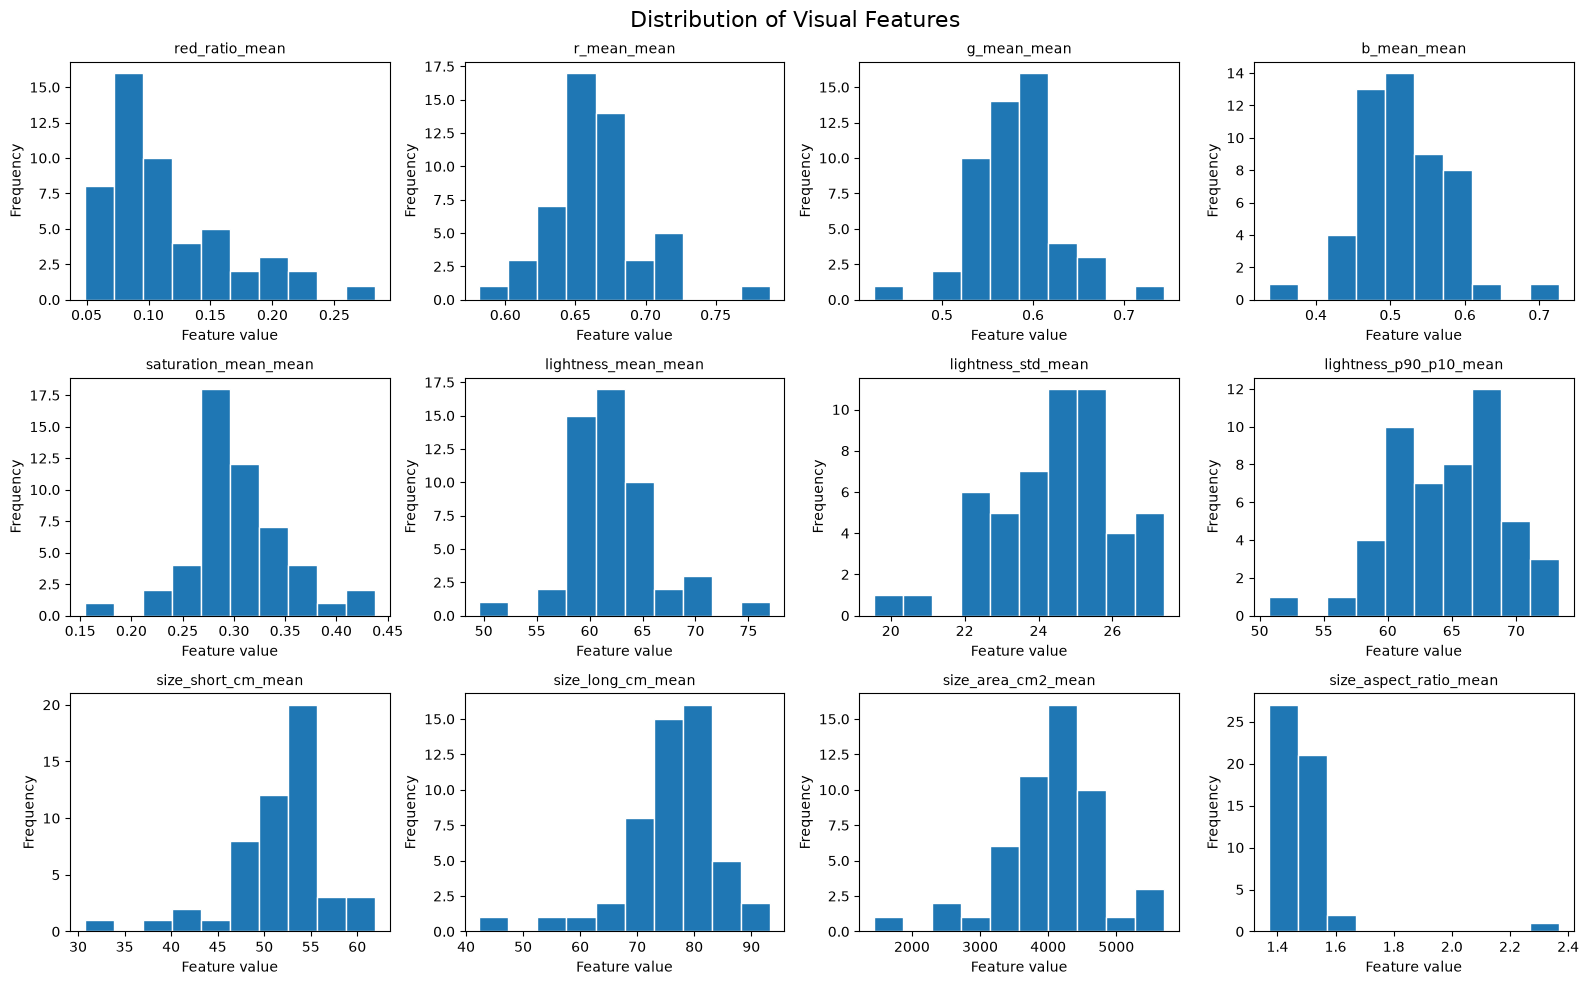

In [9]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))

for ax, feature in zip(axes.flat, visual_features):
    ax.hist(X[feature], bins=10, edgecolor="white")
    ax.set_title(feature, fontsize=10)
    ax.set_xlabel("Feature value")
    ax.set_ylabel("Frequency")

plt.suptitle("Distribution of Visual Features", fontsize=16)
plt.tight_layout()
plt.show()

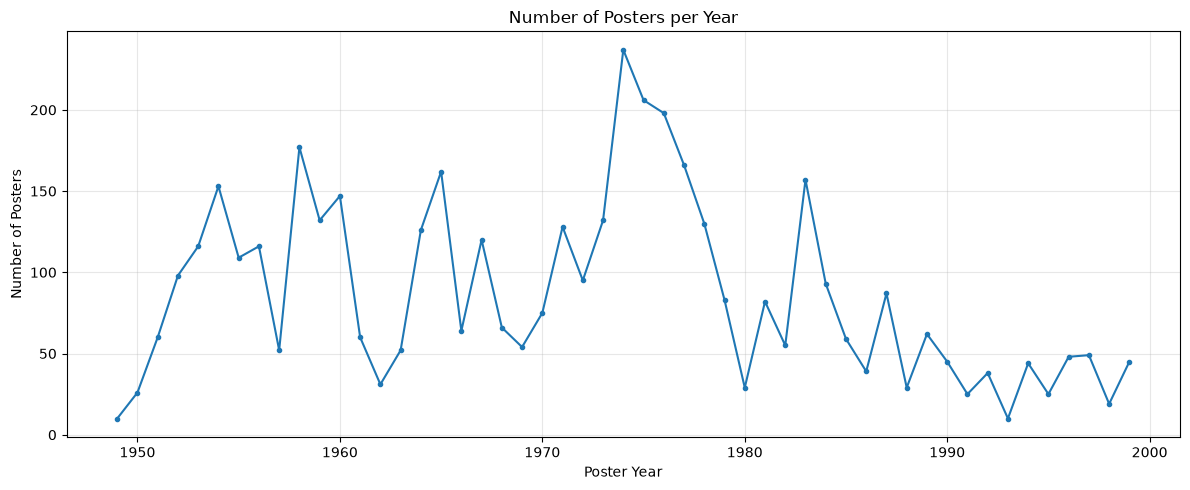

In [10]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["poster_year"],
    df["n_posters"],
    marker="o",
    markersize=3
)

plt.xlabel("Poster Year")
plt.ylabel("Number of Posters")
plt.title("Number of Posters per Year")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

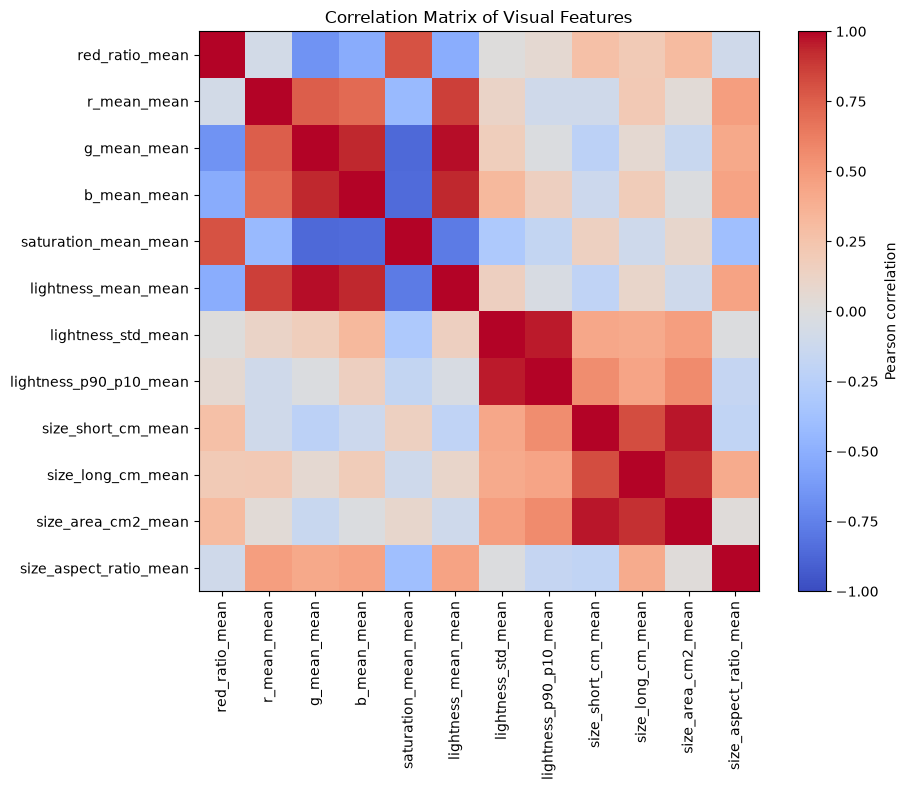

In [11]:
# Calculate Pearson correlations
corr = X.corr()

# Visualize the correlation matrix
fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(visual_features)))
ax.set_yticks(range(len(visual_features)))

ax.set_xticklabels(visual_features, rotation=90)
ax.set_yticklabels(visual_features)

fig.colorbar(im, ax=ax, label="Pearson correlation")

ax.set_title("Correlation Matrix of Visual Features")

plt.tight_layout()
plt.show()

In [13]:
# Keep only the upper triangle, excluding the diagonal
import numpy as np

mask = np.triu(
    np.ones(corr.shape, dtype=bool), k=1
)

# Extract unique feature pairs
corr_pairs = corr.where(mask).stack()

# Sort by absolute correlation
corr_pairs = corr_pairs.sort_values(
    key=abs, ascending=False
)

display(corr_pairs.head(10))

g_mean_mean         lightness_mean_mean       0.981034
size_short_cm_mean  size_area_cm2_mean        0.961835
lightness_std_mean  lightness_p90_p10_mean    0.957538
g_mean_mean         b_mean_mean               0.934873
b_mean_mean         lightness_mean_mean       0.933231
size_long_cm_mean   size_area_cm2_mean        0.910296
r_mean_mean         lightness_mean_mean       0.860949
g_mean_mean         saturation_mean_mean     -0.860062
b_mean_mean         saturation_mean_mean     -0.852110
size_short_cm_mean  size_long_cm_mean         0.816430
dtype: float64

In [14]:
# Compute correlations between each feature and the target
target_corr = X.corrwith(y)

# Sort by absolute correlation
target_corr = target_corr.sort_values(
    key=abs, ascending=False
)

display(target_corr.to_frame(name="Correlation with target"))

,Correlation with target
b_mean_mean,-0.287117
lightness_std_mean,-0.243700
size_area_cm2_mean,-0.224651
lightness_p90_p10_mean,-0.222854
size_long_cm_mean,-0.206859
r_mean_mean,-0.198406
size_short_cm_mean,-0.197906
lightness_mean_mean,-0.197850
g_mean_mean,-0.168252
saturation_mean_mean,0.162162


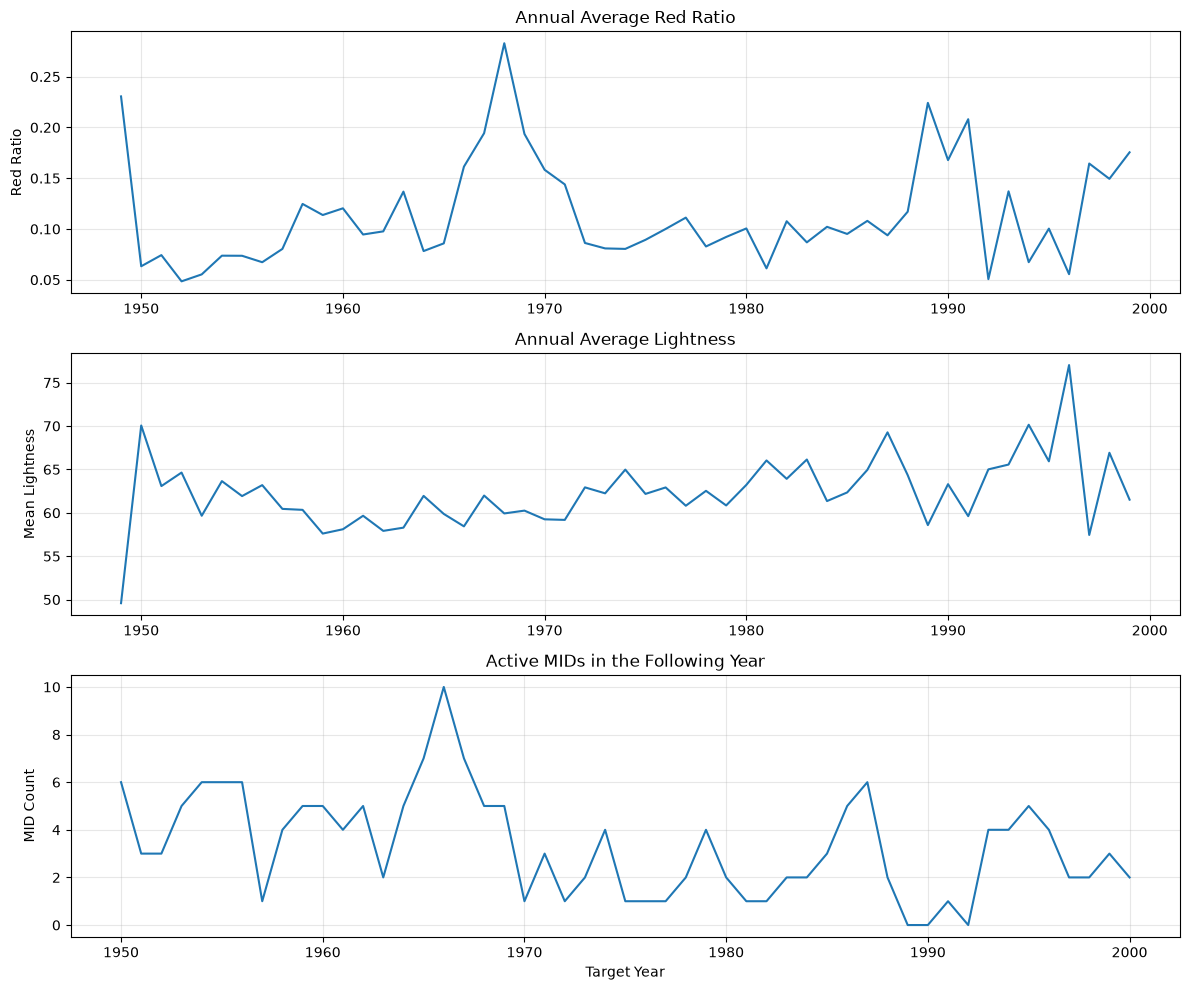

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10))

axes[0].plot(
    df["poster_year"],
    df["red_ratio_mean"]
)
axes[0].set_ylabel("Red Ratio")
axes[0].set_title("Annual Average Red Ratio")

axes[1].plot(
    df["poster_year"],
    df["lightness_mean_mean"]
)
axes[1].set_ylabel("Mean Lightness")
axes[1].set_title("Annual Average Lightness")

axes[2].plot(
    df["target_year"],
    y
)
axes[2].set_ylabel("MID Count")
axes[2].set_xlabel("Target Year")
axes[2].set_title("Active MIDs in the Following Year")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [17]:
# Autocorrelation at different lags
for lag in range(1, 6):
    r = df["y_active_mid_count"].autocorr(lag=lag)
    print(f"Lag {lag}: {r:.3f}")

Lag 1: 0.577
Lag 2: 0.299
Lag 3: 0.082
Lag 4: 0.001
Lag 5: 0.083


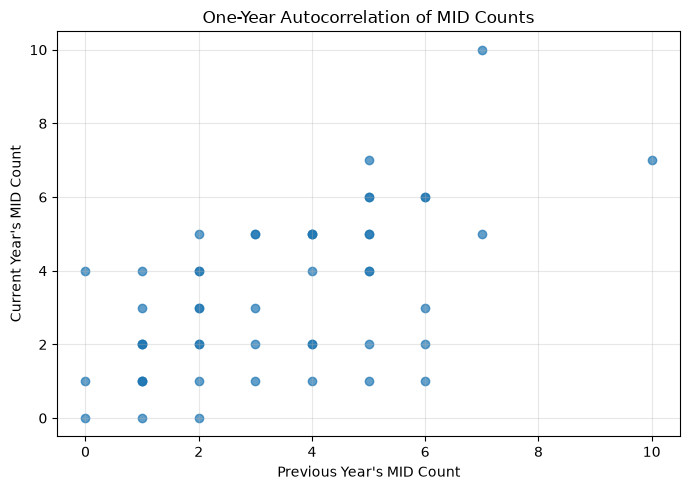

In [18]:
# Create a temporary lagged target for EDA
previous_y = df["y_active_mid_count"].shift(1)

plt.figure(figsize=(7, 5))

plt.scatter(
    previous_y,
    df["y_active_mid_count"],
    alpha=0.7
)

plt.xlabel("Previous Year's MID Count")
plt.ylabel("Current Year's MID Count")
plt.title("One-Year Autocorrelation of MID Counts")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()